# Notebook TO DO The Data Analysis

# import libraries

In [9]:
# Import analysis and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"

# data load

In [10]:


df = sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


# Saving the Data 

In [11]:
# save data into csv
df.to_csv('../Data/tips.csv', index=False)
# save data into excel
df.to_excel('../Data/tips.xlsx', index=False)


# Data Composition


Data Composition

In [12]:
df


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [13]:
# 1. Data composition report
row_count, column_count = df.shape
missing_total = int(df.isna().sum().sum())
duplicate_count = int(df.duplicated().sum())

composition = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "unique": df.nunique(dropna=True),
})
display(composition)

print(f"Dataset size: {row_count:,} rows x {column_count} columns")
print(f"Duplicate rows: {duplicate_count:,}")
print("\nNumeric summary:")
display(df.describe(include=[np.number]).T.round(2))

categorical_columns = df.select_dtypes(include=["object", "category", "string", "bool"]).columns
if len(categorical_columns):
    print("\nCategory counts:")
    for column in categorical_columns:
        display(df[column].value_counts(dropna=False).rename_axis(column).to_frame("count"))

if missing_total == 0 and duplicate_count == 0:
    print("\nReport takeaway: all fields are complete and no exact duplicate rows were found.")
elif missing_total:
    print(f"\nReport takeaway: {missing_total:,} values are missing; review the per-column missing percentages before analysis.")
else:
    print(f"\nReport takeaway: {duplicate_count:,} exact duplicate rows were found; assess them before treating rows as independent observations.")

,dtype,non_null,missing,missing_%,unique
total_bill,float64,244,0,0.0,229
tip,float64,244,0,0.0,123
sex,category,244,0,0.0,2
smoker,category,244,0,0.0,2
day,category,244,0,0.0,4
time,category,244,0,0.0,2
size,int64,244,0,0.0,6


Dataset size: 244 rows x 7 columns
Duplicate rows: 1

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
total_bill,244.0,19.79,8.90,3.07,13.35,17.8,24.13,50.81
tip,244.0,3.00,1.38,1.00,2.00,2.9,3.56,10.00
size,244.0,2.57,0.95,1.00,2.00,2.0,3.00,6.00



Category counts:


,count
sex,
Male,157
Female,87


,count
smoker,
No,151
Yes,93


,count
day,
Sat,87
Sun,76
Thur,62
Fri,19


,count
time,
Dinner,176
Lunch,68



Report takeaway: 1 exact duplicate rows were found; assess them before treating rows as independent observations.


## 2. Data distribution report

Inspect the shapes, typical values, and potential extreme values in bills, tips, and party size.

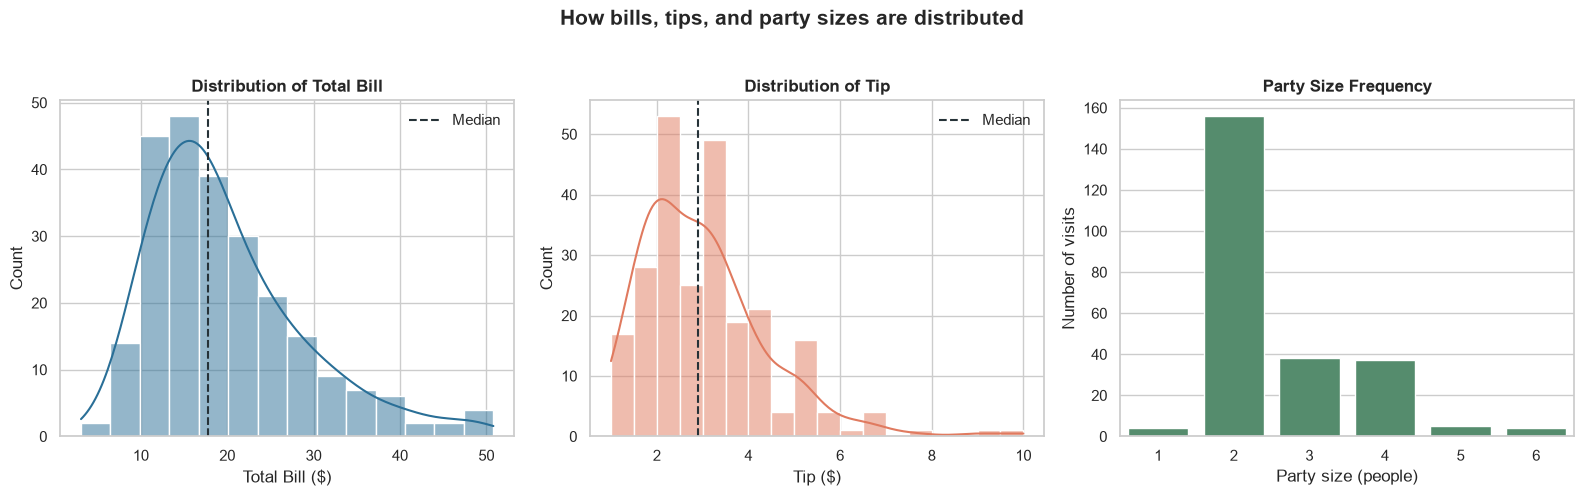

Total Bill: mean $19.79, median $17.80; the distribution is right-skewed (skewness 1.13).
Tip: mean $3.00, median $2.90; the distribution is right-skewed (skewness 1.47).
Report takeaway: parties of 2 are most common; unusually high values in the money distributions may influence averages.


In [14]:
# 2. Data distribution report
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
plot_colors = ["#2A6F97", "#E07A5F"]

for column, color, axis in zip(["total_bill", "tip"], plot_colors, axes[:2]):
    sns.histplot(data=df, x=column, kde=True, color=color, ax=axis)
    axis.axvline(df[column].median(), color="#263238", linestyle="--", linewidth=1.5, label="Median")
    axis.set_title(f"Distribution of {column.replace('_', ' ').title()}")
    axis.set_xlabel(f"{column.replace('_', ' ').title()} ($)")
    axis.legend(frameon=False)

sns.countplot(data=df, x="size", color="#4C956C", ax=axes[2])
axes[2].set_title("Party Size Frequency")
axes[2].set_xlabel("Party size (people)")
axes[2].set_ylabel("Number of visits")
fig.suptitle("How bills, tips, and party sizes are distributed", y=1.03, fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

for column in ["total_bill", "tip"]:
    mean_value = df[column].mean()
    median_value = df[column].median()
    skew_value = df[column].skew()
    shape = "right-skewed" if skew_value > 0.5 else "left-skewed" if skew_value < -0.5 else "roughly symmetric"
    print(
        f"{column.replace('_', ' ').title()}: mean ${mean_value:.2f}, median ${median_value:.2f}; "
        f"the distribution is {shape} (skewness {skew_value:.2f})."
    )
most_common_party = int(df["size"].mode().iloc[0])
print(f"Report takeaway: parties of {most_common_party} are most common; unusually high values in the money distributions may influence averages.")

## 3. Data comparison report

Compare average bills and tips across days, and tip percentages across meal times. Error bars show 95% confidence intervals around the means.

By day:


,visits,mean_bill,mean_tip,mean_tip_pct
day,,,,
Thur,62,17.68,2.77,16.13
Fri,19,17.15,2.73,16.99
Sat,87,20.44,2.99,15.32
Sun,76,21.41,3.26,16.69


By meal time:


,visits,mean_bill,mean_tip,mean_tip_pct
time,,,,
Lunch,68,17.17,2.73,16.41
Dinner,176,20.80,3.10,15.95


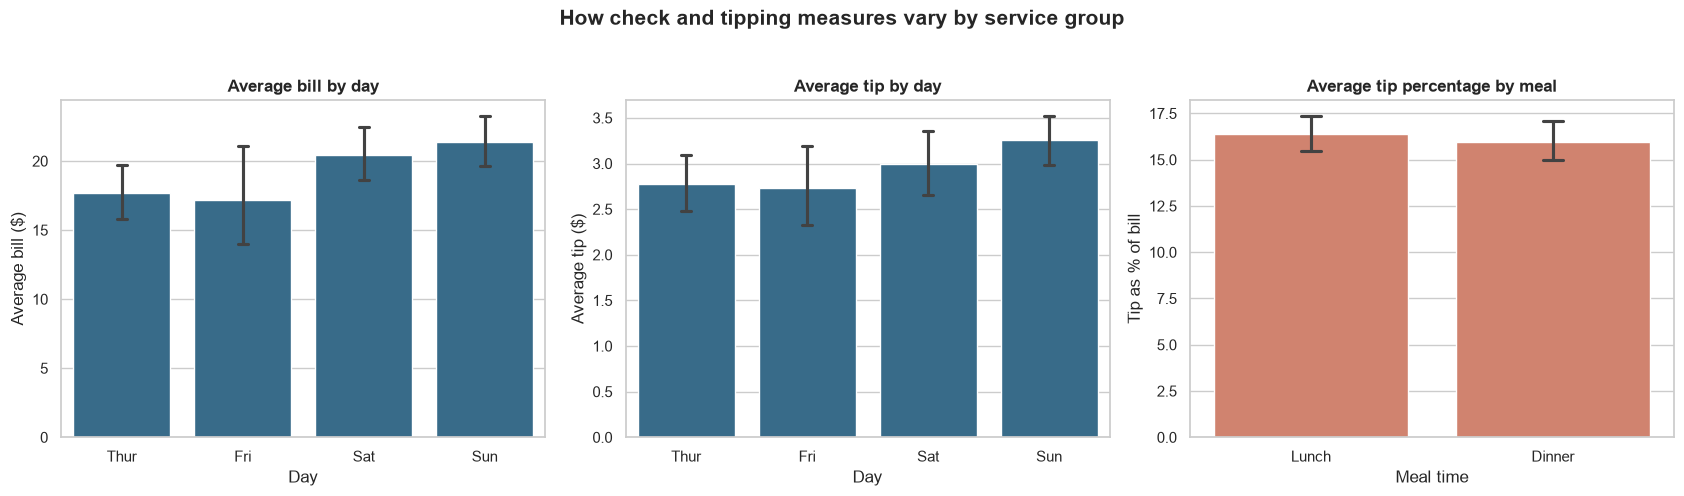

Report takeaway: the highest mean bill is on Sun ($21.41; n=76), while the lowest is on Fri ($17.15; n=19).
The highest mean tip percentage is during lunch (16.4%). Interpret group differences descriptively; sample sizes are uneven and this observational data does not establish causation.


In [15]:
# 3. Data comparison report
comparison_df = df.assign(tip_pct=np.where(df["total_bill"] > 0, 100 * df["tip"] / df["total_bill"], np.nan))
day_summary = comparison_df.groupby("day", observed=True).agg(
    visits=("total_bill", "size"),
    mean_bill=("total_bill", "mean"),
    mean_tip=("tip", "mean"),
    mean_tip_pct=("tip_pct", "mean"),
).round(2)
time_summary = comparison_df.groupby("time", observed=True).agg(
    visits=("total_bill", "size"),
    mean_bill=("total_bill", "mean"),
    mean_tip=("tip", "mean"),
    mean_tip_pct=("tip_pct", "mean"),
).round(2)

print("By day:")
display(day_summary)
print("By meal time:")
display(time_summary)

day_order = [day for day in ["Thur", "Fri", "Sat", "Sun"] if day in day_summary.index.astype(str)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
comparisons = [
    ("total_bill", "Average bill by day", "Average bill ($)"),
    ("tip", "Average tip by day", "Average tip ($)"),
]
for axis, (metric, title, ylabel) in zip(axes[:2], comparisons):
    sns.barplot(data=comparison_df, x="day", y=metric, order=day_order, errorbar=("ci", 95), capsize=0.08, color="#2A6F97", ax=axis)
    axis.set_title(title)
    axis.set_xlabel("Day")
    axis.set_ylabel(ylabel)

sns.barplot(data=comparison_df, x="time", y="tip_pct", order=["Lunch", "Dinner"], errorbar=("ci", 95), capsize=0.08, color="#E07A5F", ax=axes[2])
axes[2].set_title("Average tip percentage by meal")
axes[2].set_xlabel("Meal time")
axes[2].set_ylabel("Tip as % of bill")
fig.suptitle("How check and tipping measures vary by service group", y=1.03, fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

highest_bill_day = day_summary["mean_bill"].idxmax()
lowest_bill_day = day_summary["mean_bill"].idxmin()
highest_tip_time = time_summary["mean_tip_pct"].idxmax()
print(
    f"Report takeaway: the highest mean bill is on {highest_bill_day} "
    f"(${day_summary.loc[highest_bill_day, 'mean_bill']:.2f}; n={int(day_summary.loc[highest_bill_day, 'visits'])}), "
    f"while the lowest is on {lowest_bill_day} "
    f"(${day_summary.loc[lowest_bill_day, 'mean_bill']:.2f}; n={int(day_summary.loc[lowest_bill_day, 'visits'])})."
)
print(
    f"The highest mean tip percentage is during {highest_tip_time.lower()} "
    f"({time_summary.loc[highest_tip_time, 'mean_tip_pct']:.1f}%). Interpret group differences descriptively; "
    "sample sizes are uneven and this observational data does not establish causation."
)

## 4. Data relationship report

Explore how bill amount, tip amount, and party size move together. Correlation describes association, not cause and effect.

Pearson correlation matrix:


,total_bill,tip,size
total_bill,1.00,0.68,0.60
tip,0.68,1.00,0.49
size,0.60,0.49,1.00


Spearman rank-correlation matrix:


,total_bill,tip,size
total_bill,1.00,0.68,0.60
tip,0.68,1.00,0.47
size,0.60,0.47,1.00


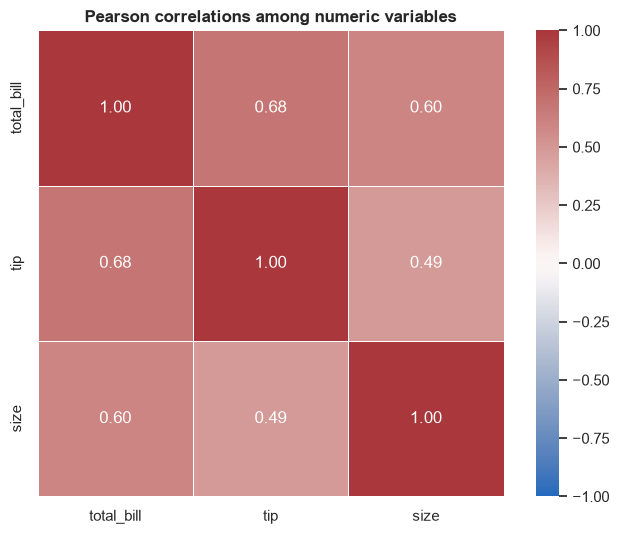

Report takeaway: bill and tip have a moderate positive linear association (Pearson r=0.68; Spearman rho=0.68). Larger bills tend to come with larger tips in this sample, but this does not show that bill size causes the tip amount.


In [16]:
# 4. Data relationship report
numeric_df = df.select_dtypes(include=[np.number])
pearson_corr = numeric_df.corr(method="pearson")
spearman_corr = numeric_df.corr(method="spearman")
print("Pearson correlation matrix:")
display(pearson_corr.round(2))
print("Spearman rank-correlation matrix:")
display(spearman_corr.round(2))

fig, axis = plt.subplots(figsize=(7, 5.5))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=axis)
axis.set_title("Pearson correlations among numeric variables")
fig.tight_layout()
plt.show()

bill_tip_pearson = pearson_corr.loc["total_bill", "tip"]
bill_tip_spearman = spearman_corr.loc["total_bill", "tip"]
correlation_strength = "strong" if abs(bill_tip_pearson) >= 0.7 else "moderate" if abs(bill_tip_pearson) >= 0.4 else "weak"
print(
    f"Report takeaway: bill and tip have a {correlation_strength} positive linear association "
    f"(Pearson r={bill_tip_pearson:.2f}; Spearman rho={bill_tip_spearman:.2f}). "
    "Larger bills tend to come with larger tips in this sample, but this does not show that bill size causes the tip amount."
)

# Interactive view for exploring individual observations
bill_values = df["total_bill"].to_numpy()
tip_values = df["tip"].to_numpy()
trend_slope, trend_intercept = np.polyfit(bill_values, tip_values, 1)
trend_x = np.linspace(bill_values.min(), bill_values.max(), 100)

relationship_fig = px.scatter(
    df,
    x="total_bill",
    y="tip",
    color="time",
    size="size",
    hover_data=["day", "sex", "smoker"],
    opacity=0.75,
    labels={"total_bill": "Total bill ($)", "tip": "Tip ($)", "time": "Meal", "size": "Party size"},
    title="Interactive relationship between bill and tip",
    color_discrete_sequence=["#2A6F97", "#E07A5F"],
)
relationship_fig.add_scatter(
    x=trend_x,
    y=trend_slope * trend_x + trend_intercept,
    mode="lines",
    name="Linear trend",
    line={"color": "#263238", "dash": "dash", "width": 2},
)
relationship_fig.update_layout(template="plotly_white", height=560)
relationship_fig.show()

In [17]:
# Export static figures for the Markdown report
from pathlib import Path

workspace_root = next(
    parent for parent in [Path.cwd(), *Path.cwd().parents]
    if (parent / "Data").is_dir() and (parent / "scripts").is_dir()
)
assets_dir = workspace_root / "reports" / "assets"
assets_dir.mkdir(parents=True, exist_ok=True)

# Composition: counts for each categorical field
categorical_columns = ["sex", "smoker", "day", "time"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, axis in zip(categorical_columns, axes.flat):
    order = df[column].value_counts().index
    sns.countplot(data=df, x=column, order=order, color="#2A6F97", ax=axis)
    axis.set_title(f"Records by {column.replace('_', ' ').title()}")
    axis.set_xlabel(column.replace("_", " ").title())
    axis.set_ylabel("Number of visits")
    axis.tick_params(axis="x", rotation=15)
fig.suptitle("Composition of the tips dataset", fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(assets_dir / "composition.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.close(fig)

# Distributions: bill, tip, and party size
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for column, color, axis in zip(["total_bill", "tip"], ["#2A6F97", "#E07A5F"], axes[:2]):
    sns.histplot(data=df, x=column, kde=True, color=color, ax=axis)
    axis.axvline(df[column].median(), color="#263238", linestyle="--", linewidth=1.5, label="Median")
    axis.set_title(f"Distribution of {column.replace('_', ' ').title()}")
    axis.set_xlabel(f"{column.replace('_', ' ').title()} ($)")
    axis.legend(frameon=False)
sns.countplot(data=df, x="size", color="#4C956C", ax=axes[2])
axes[2].set_title("Party size frequency")
axes[2].set_xlabel("Party size (people)")
axes[2].set_ylabel("Number of visits")
fig.suptitle("Distributions of bills, tips, and party sizes", fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(assets_dir / "distribution.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.close(fig)

# Comparisons: category means and 95% confidence intervals
report_df = df.assign(tip_pct=np.where(df["total_bill"] > 0, 100 * df["tip"] / df["total_bill"], np.nan))
day_order = [day for day in ["Thur", "Fri", "Sat", "Sun"] if day in df["day"].astype(str).unique()]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for axis, (metric, title, ylabel) in zip(
    axes[:2],
    [("total_bill", "Average bill by day", "Average bill ($)"), ("tip", "Average tip by day", "Average tip ($)")],
):
    sns.barplot(data=report_df, x="day", y=metric, order=day_order, errorbar=("ci", 95), capsize=0.08, color="#2A6F97", ax=axis)
    axis.set_title(title)
    axis.set_xlabel("Day")
    axis.set_ylabel(ylabel)
sns.barplot(data=report_df, x="time", y="tip_pct", order=["Lunch", "Dinner"], errorbar=("ci", 95), capsize=0.08, color="#E07A5F", ax=axes[2])
axes[2].set_title("Average tip percentage by meal")
axes[2].set_xlabel("Meal time")
axes[2].set_ylabel("Tip as % of bill")
fig.suptitle("Check and tipping measures by service group", fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(assets_dir / "comparison.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.close(fig)

# Relationships: correlation heatmap and bill-tip scatter with linear trend
correlation = df.select_dtypes(include=[np.number]).corr()
fig, axis = plt.subplots(figsize=(7, 5.5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=axis)
axis.set_title("Pearson correlations among numeric variables")
fig.tight_layout()
fig.savefig(assets_dir / "correlation_heatmap.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.close(fig)

fig, axis = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x="total_bill", y="tip", hue="time", size="size", sizes=(45, 220), alpha=0.75, palette=["#2A6F97", "#E07A5F"], ax=axis)
sns.regplot(data=df, x="total_bill", y="tip", scatter=False, ci=None, color="#263238", line_kws={"linestyle": "--", "linewidth": 2}, ax=axis)
axis.set_title("Bill amount and tip amount")
axis.set_xlabel("Total bill ($)")
axis.set_ylabel("Tip ($)")
fig.tight_layout()
fig.savefig(assets_dir / "bill_tip_relationship.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.close(fig)

print(f"Saved 5 report charts to {assets_dir}")

Saved 5 report charts to d:\python\Data Analysis\reports\assets
